## LOAN DEFAULT RISK ANALYSIS

### Python-Based Credit Risk & Loan Portfolio Analysis

**Tools Used:** Python, Pandas, Matplotlib, Power BI

**Domain:** Banking → Lending → Credit Risk

## 1. Business Context

Banks provide loans to individuals and earn interest from these loans.
However, some borrowers may fail to meet their repayment obligations.

When borrowers fail to repay their loans as required, the bank may face
financial losses and additional recovery or collection efforts.

Therefore, understanding loan default patterns is important for
credit risk management.

This project analyzes loan-level data to understand how observed
default rates vary across different borrower, credit, financial,
and loan characteristics.

## 2. Business Problem

The bank wants to understand how observed loan default rates vary
across different borrower and loan characteristics.

The analysis will focus on identifying segments with relatively
higher observed default rates and investigating the characteristics
associated with these patterns.

## 3. Project Objectives

### Objective 1 — Borrower Profile
Analyze how observed default rates vary across borrower characteristics
such as income, age, education, employment type, marital status,
and dependents.

### Objective 2 — Credit & Financial Risk
Analyze how credit and financial characteristics such as credit score,
DTI ratio, number of credit lines, employment duration, and mortgage
status are associated with observed default patterns.

### Objective 3 — Loan Characteristics
Analyze how observed default rates vary across loan amount,
interest rate, loan term, loan purpose, and co-signer status.

### Objective 4 — Risk Segmentation
Identify borrower and loan segments that show relatively higher
observed default rates and investigate combinations of characteristics
associated with these patterns.

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 4. Data Loading

The loan dataset is loaded into Python using Pandas for data
preparation, quality checks, and exploratory analysis.

In [56]:
df = pd.read_csv("C:/Users/vaani/Downloads/Loan_Default.csv")
print(df)

            LoanID  Age  Income  LoanAmount  CreditScore  MonthsEmployed  \
0       I38PQUQS96   56   85994       50587          520              80   
1       HPSK72WA7R   69   50432      124440          458              15   
2       C1OZ6DPJ8Y   46   84208      129188          451              26   
3       V2KKSFM3UN   32   31713       44799          743               0   
4       EY08JDHTZP   60   20437        9139          633               8   
...            ...  ...     ...         ...          ...             ...   
255342  8C6S86ESGC   19   37979      210682          541             109   
255343  98R4KDHNND   32   51953      189899          511              14   
255344  XQK1UUUNGP   56   84820      208294          597              70   
255345  JAO28CPL4H   42   85109       60575          809              40   
255346  ZTH91CGL0B   62   22418       18481          636             113   

        NumCreditLines  InterestRate  LoanTerm  DTIRatio    Education  \
0             

In [38]:
df.shape

(255347, 19)

### Dataset Size

The dataset contains 255,347 loan records and 18 columns.

Each row represents a loan record, while the columns contain
information about the borrower, credit profile, loan characteristics,
and loan default outcome.

In [39]:
df.head()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default,Income_Group
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0,Medium
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0,Medium
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1,Medium
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0,Low
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0,Low


In [41]:
df.columns

Index(['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore',
       'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm',
       'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus',
       'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default',
       'Income_Group'],
      dtype='object')

## 5. Dataset Understanding

The dataset contains information from four major areas:

1. Borrower Profile
2. Credit & Financial Profile
3. Loan Profile
4. Loan Outcome

Understanding these columns is important before starting the business
analysis because each variable represents a different aspect of the
borrower or loan.

### Key Column Groups

| Category | Columns |
|---|---|
| Borrower Profile | Age, Income, Education, EmploymentType, MaritalStatus, HasDependents |
| Credit Profile | CreditScore, NumCreditLines |
| Employment | MonthsEmployed, EmploymentType |
| Loan Profile | LoanAmount, InterestRate, LoanTerm, LoanPurpose |
| Financial Profile | DTIRatio, HasMortgage |
| Additional Risk Context | HasCoSigner |
| Outcome | Default |
| Identifier | LoanID |

In [13]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  object 
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  object 
 11  EmploymentType  255347 non-null  object 
 12  MaritalStatus   255347 non-null  object 
 13  HasMortgage     255347 non-null  object 
 14  HasDependents   255347 non-null  object 
 15  LoanPurpose     255347 non-null  object 
 16  HasCoSigner     255347 non-null  object 
 17  Default   

## 6. Data Quality Check

Before performing business analysis, the dataset is checked for:

- Missing values
- Duplicate loan records
- Data types
- Target variable distribution

In [14]:
df.isnull().sum()

LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64

### Missing Value Check

No missing values were found across the 18 columns.

Therefore, no missing-value treatment was required before the
exploratory analysis.

In [58]:
df.dtypes

LoanID             object
Age                 int64
Income              int64
LoanAmount          int64
CreditScore         int64
MonthsEmployed      int64
NumCreditLines      int64
InterestRate      float64
LoanTerm            int64
DTIRatio          float64
Education          object
EmploymentType     object
MaritalStatus      object
HasMortgage        object
HasDependents      object
LoanPurpose        object
HasCoSigner        object
Default             int64
dtype: object

In [15]:
df['LoanID'].duplicated().sum()

np.int64(0)

### Duplicate Check

No duplicate LoanID values were found.

This indicates that each LoanID appears uniquely in the dataset.

In [17]:
df['Default'].value_counts()

Default
0    225694
1     29653
Name: count, dtype: int64

### Default Distribution

The dataset contains:

- 225,694 non-defaulted loans
- 29,653 defaulted loans

The target variable is therefore suitable for calculating the
overall observed default rate.

## 7. Overall Loan Overview

Before analyzing individual borrower and loan characteristics,
we first establish a baseline view of the overall loan.

This provides a reference point against which different segments
can later be compared.

In [43]:
total_loans = len(df)

defaulted_loans = (df['Default'] == 1).sum()

non_defaulted_loans = (df['Default'] == 0).sum()

default_rate = defaulted_loans / total_loans * 100

print("Total Loans:", total_loans)
print("Defaulted Loans:", defaulted_loans)
print("Non-defaulted Loans:", non_defaulted_loans)
print("Default Rate:", round(default_rate, 2), "%")

Total Loans: 255347
Defaulted Loans: 29653
Non-defaulted Loans: 225694
Default Rate: 11.61 %


In [44]:
kpi = pd.DataFrame({
    'KPI': [
        'Total Loans',
        'Defaulted Loans',
        'Non-defaulted Loans',
        'Default Rate'
    ],
    'Value': [
        total_loans,
        defaulted_loans,
        non_defaulted_loans,
        round(default_rate, 2)
    ]
})

kpi

,KPI,Value
0,Total Loans,255347.00
1,Defaulted Loans,29653.00
2,Non-defaulted Loans,225694.00
3,Default Rate,11.61


### Portfolio Baseline

Across the 255,347 loan records, 29,653 loans are observed as
defaulted, resulting in an overall observed default rate of 11.62%.

This 11.62% rate will be used as a baseline when comparing
different borrower and loan segments.

# 8. Objective 1 — Borrower Profile Analysis

The first objective is to understand how observed default rates vary
across different borrower characteristics.

The analysis begins with income because income represents the
borrower's earning level and may be relevant when evaluating
repayment-related patterns.

## 8.1 Income Analysis

### Business Question

How does the observed default rate vary across different income groups?

In [24]:
df['Income'].describe()

count    255347.000000
mean      82499.304597
std       38963.013729
min       15000.000000
25%       48825.500000
50%       82466.000000
75%      116219.000000
max      149999.000000
Name: Income, dtype: float64

### Why Create Income Groups?

Income is a continuous numerical variable, which makes it difficult
to compare individual income values from a business perspective.

Therefore, borrowers are grouped into three broad income segments:

- Low Income: 0–50,000
- Medium Income: 50,000–100,000
- High Income: 100,000–150,000

This allows the bank to compare observed default rates across
different income segments.

In [28]:
df['Income_Group'] = pd.cut(
    df['Income'],
    bins=[0, 50000, 100000, 150000],
    labels=['Low', 'Medium', 'High'],
    include_lowest=True
)

In [29]:
df['Income_Group'].value_counts()

Income_Group
Medium    94683
High      94565
Low       66099
Name: count, dtype: int64

In [30]:
income_analysis = df.groupby('Income_Group', observed=True).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

income_analysis['Default_Rate'] = (
    income_analysis['Defaulted_Loans']
    / income_analysis['Total_Loans'] * 100
)

income_analysis

,Total_Loans,Defaulted_Loans,Default_Rate
Income_Group,,,
Low,66099,11344,17.162136
Medium,94683,9700,10.244711
High,94565,8609,9.103791


In [32]:
highest = income_analysis['Default_Rate'].max()
lowest = income_analysis['Default_Rate'].min()

difference = highest - lowest

print("Highest Default Rate:", round(highest, 2), "%")
print("Lowest Default Rate:", round(lowest, 2), "%")
print("Difference:", round(difference, 2), "percentage points")

Highest Default Rate: 17.16 %
Lowest Default Rate: 9.1 %
Difference: 8.06 percentage points


## Key Observation

The observed default rate is highest among low-income borrowers at 17.16% and lowest among high-income borrowers at 9.10%.

Overall, the observed default rate decreases as income increases.

The difference between the highest and lowest observed default rates is 8.06 percentage points.

This observation indicates that income level is an important segment to investigate further. However, this analysis does not establish that income itself causes loan default.

The next step is to investigate whether other borrower or financial characteristics are associated with the higher observed default rate among low-income borrowers.

### Business Interpretation

The analysis shows that different income segments have different
observed default rates in the loan portfolio.

Low-income borrowers show a relatively higher observed default rate
compared with medium- and high-income borrowers.

However, this analysis does not establish that income itself causes
loan default. Other borrower, credit, financial, and loan
characteristics need to be investigated to understand the pattern
further.

### Follow-up Investigation

The low-income segment shows the highest observed default rate.

To investigate this pattern further, the next analysis will examine
whether borrowers with different credit profiles show different
observed default rates.

### Follow-up Business Question

Among borrowers with different income levels, how does the observed
default rate vary across Credit Score groups?

## 8.2  Credit Score Analysis

### Business Question

How does the observed default rate vary across different Credit Score groups?

### Why are we analyzing Credit Score?

Credit Score is an indicator of a borrower's credit profile and past
credit behaviour. Comparing observed default rates across Credit Score
groups can help us understand whether different credit-score segments
show different default patterns.

In [46]:
df['CreditScore'].describe()

count    255347.000000
mean        574.264346
std         158.903867
min         300.000000
25%         437.000000
50%         574.000000
75%         712.000000
max         849.000000
Name: CreditScore, dtype: float64

### Creating Credit Score Groups

Credit Score is a continuous numerical variable, so individual scores
are grouped into four broad segments to make comparison easier.

The groups used for this analysis are:

- 300–449: Low Credit Score
- 450–599: Medium-Low Credit Score
- 600–749: Medium-High Credit Score
- 750–849: High Credit Score

These groups allow us to compare observed default rates across
different credit-score segments.

In [47]:
df['CreditScore_Group'] = pd.cut(
    df['CreditScore'],
    bins=[299, 449, 599, 749, 849],
    labels=[
        'Low',
        'Medium-Low',
        'Medium-High',
        'High'
    ]
)

In [49]:
df['CreditScore_Group'].value_counts().sort_index()

CreditScore_Group
Low            69746
Medium-Low     69737
Medium-High    69290
High           46574
Name: count, dtype: int64

### Credit Score Group Analysis

The number of loans in each Credit Score group is now available.

The next step is to compare the number of defaulted loans and the
observed default rate across these Credit Score groups.

This will help us understand whether borrowers with different
credit-score profiles show different observed default patterns.

In [50]:
credit_analysis = df.groupby('CreditScore_Group', observed=True).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

credit_analysis['Default_Rate'] = (
    credit_analysis['Defaulted_Loans']
    / credit_analysis['Total_Loans'] * 100
)

credit_analysis

,Total_Loans,Defaulted_Loans,Default_Rate
CreditScore_Group,,,
Low,69746,9063,12.994294
Medium-Low,69737,8314,11.921935
Medium-High,69290,7580,10.939530
High,46574,4696,10.082879


In [51]:
highest = credit_analysis['Default_Rate'].max()
lowest = credit_analysis['Default_Rate'].min()

difference = highest - lowest

print("Highest Default Rate:", round(highest, 2), "%")
print("Lowest Default Rate:", round(lowest, 2), "%")
print("Difference:", round(difference, 2), "percentage points")

Highest Default Rate: 12.99 %
Lowest Default Rate: 10.08 %
Difference: 2.91 percentage points


### Key Observation

The observed default rate is highest among the Low Credit Score group
at 12.99% and lowest among the High Credit Score group at 10.08%.

Overall, the observed default rate decreases as the Credit Score group
increases.

The difference between the highest and lowest observed default rates
is approximately 2.91 percentage points.

### Deeper Investigation: Income and Credit Score

The income analysis showed that low-income borrowers have the highest
observed default rate.

The Credit Score analysis also showed that lower Credit Score groups
have relatively higher observed default rates.

To investigate whether these two characteristics show different
default patterns when considered together, the next analysis examines
observed default rates across Income and Credit Score groups.

### Business Question

How does the observed default rate vary across Credit Score groups
within different income segments?

In [52]:
income_credit_analysis = df.groupby(
    ['Income_Group', 'CreditScore_Group'],
    observed=True
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

income_credit_analysis['Default_Rate'] = (
    income_credit_analysis['Defaulted_Loans']
    / income_credit_analysis['Total_Loans'] * 100
)

income_credit_analysis

Total_Loans  Defaulted_Loans  Default_Rate
Income_Group CreditScore_Group                                            
Low          Low                      18163             3468     19.093762
             Medium-Low               17865             3090     17.296390
             Medium-High              17956             2958     16.473602
             High                     12115             1828     15.088733
Medium       Low                      25752             2933     11.389407
             Medium-Low               25788             2664     10.330386
             Medium-High              25901             2573      9.933979
             High                     17242             1530      8.873681
High         Low                      25831             2662     10.305447
             Medium-Low               26084             2560      9.814446
             Medium-High              25433             2049      8.056462
             High                     17217             1338      7.771389

In [53]:
highest = income_credit_analysis['Default_Rate'].max()
lowest = income_credit_analysis['Default_Rate'].min()

difference = highest - lowest

print("Highest Default Rate:", round(highest, 2), "%")
print("Lowest Default Rate:", round(lowest, 2), "%")
print("Difference:", round(difference, 2), "percentage points")

Highest Default Rate: 19.09 %
Lowest Default Rate: 7.77 %
Difference: 11.32 percentage points


### Key Observation

When Income and Credit Score are considered together, the observed
default rate varies considerably across segments.

The Low Income + Low Credit Score segment has the highest observed
default rate at 19.09%.

The High Income + High Credit Score segment has the lowest observed
default rate at 7.77%.

The difference between these two segments is 11.32 percentage points.

Within each income group, the observed default rate generally
decreases as the Credit Score group increases.

The pattern is also visible across income groups, with higher-income
segments generally showing lower observed default rates for the same
Credit Score group.

### Business Interpretation

The combined analysis provides a more detailed view than analyzing
Income or Credit Score separately.

The highest observed default rate is concentrated in the segment
combining lower income and lower Credit Score, while the lowest
observed default rate is observed among higher-income borrowers with
higher Credit Scores.

This suggests that borrower segmentation using multiple
characteristics can reveal differences that may not be visible when
examining a single variable alone.

However, these results describe associations observed in the dataset
and do not establish that income or Credit Score independently causes
loan default.

### Visualization

The following visualization compares observed default rates across
Income and Credit Score segments.

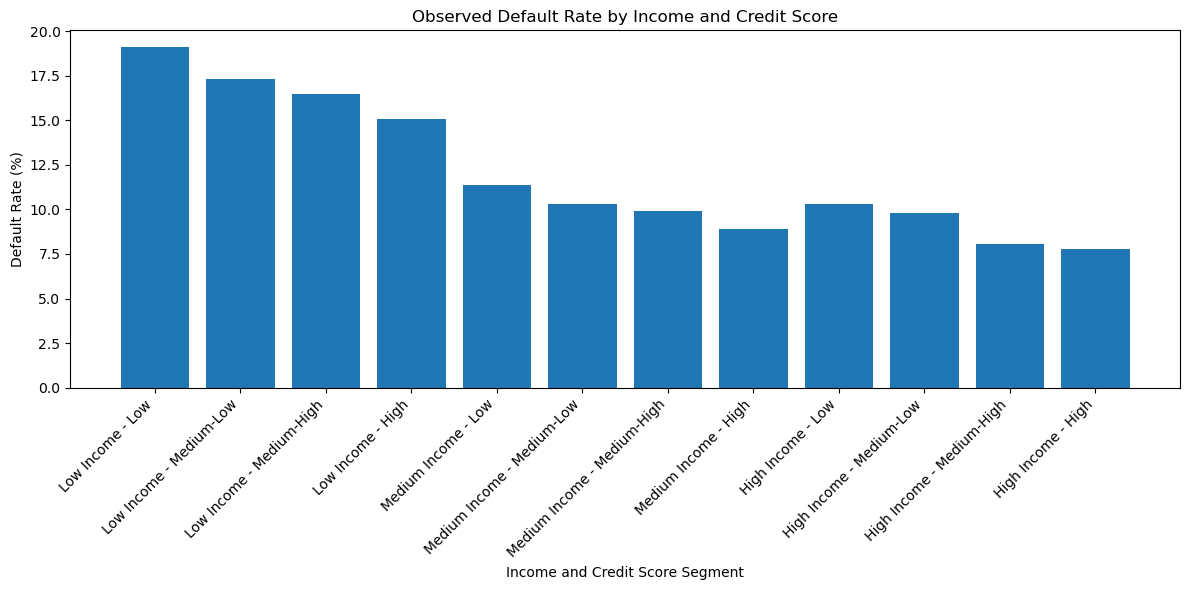

In [55]:
plot_data = income_credit_analysis.reset_index()

plot_data['Segment'] = (
    plot_data['Income_Group'].astype(str)
    + " Income - "
    + plot_data['CreditScore_Group'].astype(str)
)

plt.figure(figsize=(12, 6))

plt.bar(
    plot_data['Segment'],
    plot_data['Default_Rate']
)

plt.title('Observed Default Rate by Income and Credit Score')
plt.xlabel('Income and Credit Score Segment')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

## 8.3 Age Analysis

### Business Question

How does the observed default rate vary across different age groups?

### Why are we analyzing Age?

Age represents an important borrower characteristic.

Instead of comparing individual ages, borrowers are grouped into
broader age segments so that observed default rates can be compared
more easily across different stages of the borrower's age.

In [59]:
df['Age'].describe()

count    255347.000000
mean         43.498306
std          14.990258
min          18.000000
25%          31.000000
50%          43.000000
75%          56.000000
max          69.000000
Name: Age, dtype: float64

### Creating Age Groups

For this analysis, borrowers are grouped into the following age segments:

- 18–30: Young Borrowers
- 31–45: Early-Mid Career
- 46–60: Mid/Late Career
- 61+: Older Borrowers

These groups provide a simple business-oriented way to compare
observed default rates across different age segments.

In [62]:
df['Age_Group'] = pd.cut(
    df['Age'],
    bins=[17, 30, 45, 60, 100],
    labels=[
        '18-30',
        '31-45',
        '46-60',
        '61+'
    ]
)

In [63]:
age_analysis = df.groupby(
    'Age_Group',
    observed=True
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

age_analysis['Default_Rate'] = (
    age_analysis['Defaulted_Loans']
    / age_analysis['Total_Loans'] * 100
)

age_analysis

,Total_Loans,Defaulted_Loans,Default_Rate
Age_Group,,,
18-30,63577,12325,19.385941
31-45,74067,9403,12.695262
46-60,73501,5691,7.742752
61+,44202,2234,5.054070


In [64]:
highest = age_analysis['Default_Rate'].max()
lowest = age_analysis['Default_Rate'].min()

difference = highest - lowest

print("Highest Default Rate:", round(highest, 2), "%")
print("Lowest Default Rate:", round(lowest, 2), "%")
print("Difference:", round(difference, 2), "percentage points")

Highest Default Rate: 19.39 %
Lowest Default Rate: 5.05 %
Difference: 14.33 percentage points


### Key Observation

The observed default rate is highest among 18–30-year-old borrowers
at 19.39% and lowest among borrowers aged 61+ at 5.05%.

Overall, the observed default rate decreases as age increases.

The difference between the highest and lowest observed default rates
is 14.33 percentage points.

### Business Interpretation

The analysis shows that observed default rates differ substantially
across age groups.

The 18–30 age group shows a relatively higher observed default rate,
while the 61+ age group shows a relatively lower observed default rate.

This indicates that age-based segmentation can help identify borrower
segments with different observed default patterns.

However, this analysis does not establish that age itself causes
loan default. Other borrower, credit, financial, and loan
characteristics should be investigated to understand the pattern
further.

### Follow-up Investigation

The 18–30 age group shows the highest observed default rate.

To investigate this pattern further, the next analysis will examine
whether Credit Score shows different default patterns within different
age groups.

### Follow-up Business Question

Among different age groups, how does the observed default rate vary
across Credit Score groups?

In [67]:
age_credit_analysis = df.groupby(
    ['Age_Group', 'CreditScore_Group'],
    observed=True
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

age_credit_analysis['Default_Rate'] = (
    age_credit_analysis['Defaulted_Loans']
    / age_credit_analysis['Total_Loans'] * 100
)

age_credit_analysis

Total_Loans  Defaulted_Loans  Default_Rate
Age_Group CreditScore_Group                                            
18-30     Low                      17429             3793     21.762580
          Medium-Low               17285             3425     19.814868
          Medium-High              17246             3142     18.218717
          High                     11617             1965     16.914866
31-45     Low                      20083             2847     14.176169
          Medium-Low               20325             2681     13.190652
          Medium-High              20145             2410     11.963266
          High                     13514             1465     10.840610
46-60     Low                      20124             1731      8.601670
          Medium-Low               20247             1588      7.843137
          Medium-High              19796             1457      7.360073
          High                     13334              915      6.862157
61+       Low                      12110              692      5.714286
          Medium-Low               11880              620      5.218855
          Medium-High              12103              571      4.717839
          High                      8109              351      4.328524

In [68]:
highest = age_credit_analysis['Default_Rate'].max()
lowest = age_credit_analysis['Default_Rate'].min()

difference = highest - lowest

print("Highest Default Rate:", round(highest, 2), "%")
print("Lowest Default Rate:", round(lowest, 2), "%")
print("Difference:", round(difference, 2), "percentage points")

Highest Default Rate: 21.76 %
Lowest Default Rate: 4.33 %
Difference: 17.43 percentage points


### Key Observation

When Age and Credit Score are considered together, the observed
default rate varies substantially across the combined segments.

The 18–30 age group with Low Credit Score has the highest observed
default rate at 21.76%.

The 61+ age group with High Credit Score has the lowest observed
default rate at 4.33%.

The difference between these two segments is 17.43 percentage points.

Within each age group, the observed default rate generally decreases
as Credit Score increases.

### Business Interpretation

The combined analysis provides a more detailed view than analyzing
Age or Credit Score separately.

The highest observed default rate is seen in the combination of
younger age and lower Credit Score, while the lowest observed default
rate is seen in the combination of older age and higher Credit Score.

This shows that combining borrower characteristics can reveal
different observed default patterns across borrower segments.

However, these results describe associations observed in the dataset
and do not establish that Age or Credit Score independently causes
loan default.

### Visualization

The following visualization compares observed default rates across
Age and Credit Score segments.

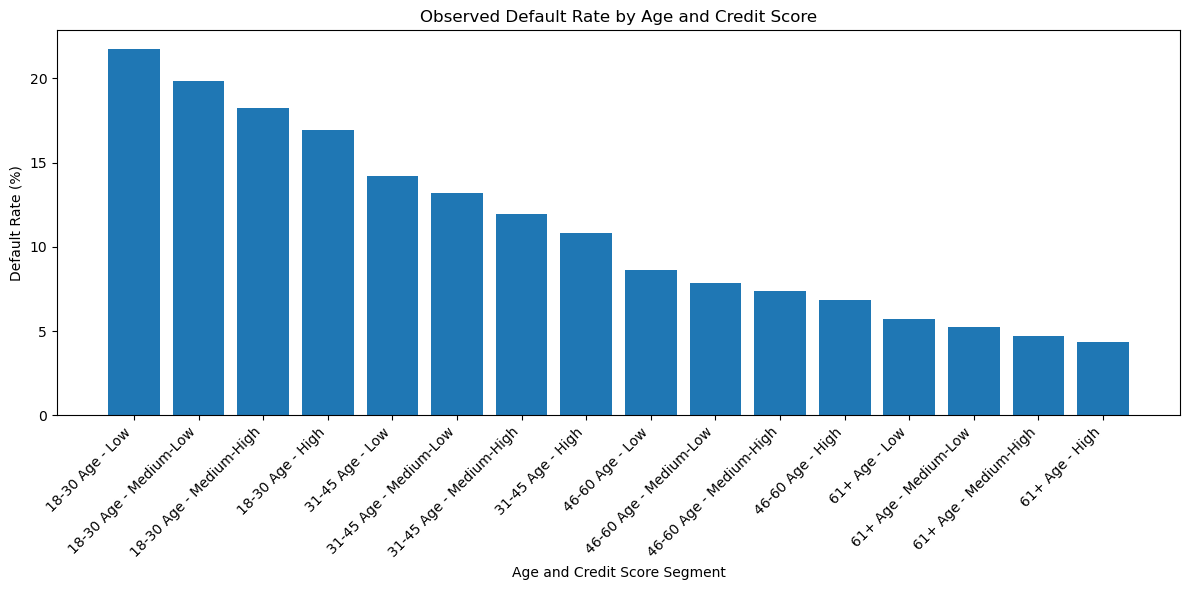

In [69]:
plot_data = age_credit_analysis.reset_index()

plot_data['Segment'] = (
    plot_data['Age_Group'].astype(str)
    + " Age - "
    + plot_data['CreditScore_Group'].astype(str)
)

plt.figure(figsize=(12, 6))

plt.bar(
    plot_data['Segment'],
    plot_data['Default_Rate']
)

plt.title('Observed Default Rate by Age and Credit Score')
plt.xlabel('Age and Credit Score Segment')
plt.ylabel('Default Rate (%)')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

## 8.4 Education Analysis

### Business Question

How does the observed default rate vary across different education levels?

### Why are we analyzing Education?

Education is a borrower profile characteristic that may help us
understand whether observed default rates differ across borrowers
with different educational backgrounds.

The analysis will compare the observed default rate across education
categories.

In [70]:
df['Education'].value_counts()

Education
Bachelor's     64366
High School    63903
Master's       63541
PhD            63537
Name: count, dtype: int64

In [71]:
education_analysis = df.groupby(
    'Education'
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

education_analysis['Default_Rate'] = (
    education_analysis['Defaulted_Loans']
    / education_analysis['Total_Loans'] * 100
)

education_analysis

,Total_Loans,Defaulted_Loans,Default_Rate
Education,,,
Bachelor's,64366,7789,12.101109
High School,63903,8230,12.878895
Master's,63541,6908,10.871721
PhD,63537,6726,10.585958



### Key Observation

The observed default rate is highest among High School borrowers at
12.88% and lowest among PhD borrowers at 10.59%.

Overall, the observed default rate generally decreases as the
education level increases.

In [72]:
highest = education_analysis['Default_Rate'].max()
lowest = education_analysis['Default_Rate'].min()

difference = highest - lowest

print("Highest Default Rate:", round(highest, 2), "%")
print("Lowest Default Rate:", round(lowest, 2), "%")
print("Difference:", round(difference, 2), "percentage points")

Highest Default Rate: 12.88 %
Lowest Default Rate: 10.59 %
Difference: 2.29 percentage points


### Business Interpretation

The analysis shows some variation in observed default rates across
education levels.

High School borrowers show the highest observed default rate at 12.88%,
while PhD borrowers show the lowest observed default rate at 10.59%.

The difference between the highest and lowest observed default rates
is 2.29 percentage points.

Compared with the patterns observed for Income and Age, the variation
across education levels is relatively smaller.

However, these results describe observed associations and do not
establish that education level itself causes loan default.

## 8.5 Employment Type Analysis

In [73]:
df['EmploymentType'].value_counts()

EmploymentType
Part-time        64161
Unemployed       63824
Self-employed    63706
Full-time        63656
Name: count, dtype: int64

In [74]:
employment_analysis = df.groupby(
    'EmploymentType'
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

employment_analysis['Default_Rate'] = (
    employment_analysis['Defaulted_Loans']
    / employment_analysis['Total_Loans'] * 100
)

employment_analysis

,Total_Loans,Defaulted_Loans,Default_Rate
EmploymentType,,,
Full-time,63656,6024,9.463366
Part-time,64161,7677,11.965213
Self-employed,63706,7302,11.462029
Unemployed,63824,8650,13.552895


### Key Observation

The observed default rate is highest among Unemployed borrowers at
13.55% and lowest among Full-time employed borrowers at 9.46%.

Overall, Unemployed borrowers show the highest observed default rate,
while Full-time employed borrowers show the lowest observed default
rate.

In [76]:
highest = employment_analysis['Default_Rate'].max()
lowest = employment_analysis['Default_Rate'].min()

difference = highest - lowest

print("Highest Default Rate:", round(highest, 2), "%")
print("Lowest Default Rate:", round(lowest, 2), "%")
print("Difference:", round(difference, 2), "percentage points")

Highest Default Rate: 13.55 %
Lowest Default Rate: 9.46 %
Difference: 4.09 percentage points


### Business Interpretation

The analysis shows that observed default rates vary across different
employment types.

Unemployed borrowers show the highest observed default rate at 13.55%,
while Full-time employed borrowers show the lowest at 9.46%.

The difference between the highest and lowest observed default rates
is 4.09 percentage points.

These results describe observed differences across employment groups
and do not establish that employment type itself causes loan default.

##  8.6 Marital Status Analysis

In [77]:
df['MaritalStatus'].value_counts()

MaritalStatus
Married     85302
Divorced    85033
Single      85012
Name: count, dtype: int64

In [78]:
marital_analysis = df.groupby(
    'MaritalStatus'
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

marital_analysis['Default_Rate'] = (
    marital_analysis['Defaulted_Loans']
    / marital_analysis['Total_Loans'] * 100
)

marital_analysis

,Total_Loans,Defaulted_Loans,Default_Rate
MaritalStatus,,,
Divorced,85033,10657,12.532781
Married,85302,8869,10.397177
Single,85012,10127,11.912436


### Key Observation

The observed default rate is highest among Divorced borrowers at
12.53% and lowest among Married borrowers at 10.40%.

Overall, the observed default rate varies across the three
marital-status groups.

### Business Interpretation

The analysis shows that observed default rates vary across
different marital-status groups.

Divorced borrowers show the highest observed default rate at
12.53%, while married borrowers show the lowest at 10.40%.

This indicates that different marital-status groups exhibit
different observed default patterns in the loan portfolio.

However, these results describe an observed association and do not
establish that marital status itself causes loan default.

## 8.7 HasDependent Analysis

### Business Question

How does the observed default rate vary across different dependent-status groups?

In [79]:
df['HasDependents'].value_counts()4asA

HasDependents
Yes    127742
No     127605
Name: count, dtype: int64

In [80]:
dependents_analysis = df.groupby(
    'HasDependents'
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

dependents_analysis['Default_Rate'] = (
    dependents_analysis['Defaulted_Loans']
    / dependents_analysis['Total_Loans'] * 100
)

dependents_analysis

,Total_Loans,Defaulted_Loans,Default_Rate
HasDependents,,,
No,127605,16237,12.724423
Yes,127742,13416,10.502419


### Key Observation

The observed default rate is highest among borrowers without
dependents at 12.72% and lowest among borrowers with dependents
at 10.50%.

Overall, the observed default rate varies between borrowers with
and without dependents.

### Business Interpretation

The analysis shows that observed default rates vary between borrowers
with and without dependents.

Borrowers without dependents show the higher observed default rate
at 12.72%, while borrowers with dependents show the lower observed
default rate at 10.50%.

This indicates that the two dependent-status groups exhibit different
observed default patterns in the loan portfolio.

However, this analysis does not establish that having or not having
dependents causes loan default.

# 9. Objective 2 — Credit & Financial Risk

The second objective is to understand how credit and financial
characteristics are associated with observed loan default patterns.

The analysis will examine variables such as Credit Score, DTI Ratio,
Number of Credit Lines, Months Employed, and Mortgage Status.

### 9.1 Credit Score Analysis

Credit Score represents a borrower's credit profile and is an important
variable when analyzing loan default patterns.

### Business Question

How does the observed default rate vary across different Credit Score groups?

In [82]:
df['CreditScore'].describe()

count    255347.000000
mean        574.264346
std         158.903867
min         300.000000
25%         437.000000
50%         574.000000
75%         712.000000
max         849.000000
Name: CreditScore, dtype: float64

In [83]:
df['CreditScore_Group'] = pd.cut(
    df['CreditScore'],
    bins=[299, 449, 599, 749, 849],
    labels=[
        'Low',
        'Medium-Low',
        'Medium-High',
        'High'
    ]
)

In [84]:
credit_analysis = df.groupby(
    'CreditScore_Group',
    observed=True
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

credit_analysis['Default_Rate'] = (
    credit_analysis['Defaulted_Loans']
    / credit_analysis['Total_Loans'] * 100
)

credit_analysis

,Total_Loans,Defaulted_Loans,Default_Rate
CreditScore_Group,,,
Low,69746,9063,12.994294
Medium-Low,69737,8314,11.921935
Medium-High,69290,7580,10.939530
High,46574,4696,10.082879


### Key Observation

The observed default rate is highest among the Low Credit Score group
at 12.99% and lowest among the High Credit Score group at 10.08%.

Overall, the observed default rate generally decreases as the Credit
Score group increases.

### Business Interpretation

Lower Credit Score groups show relatively higher observed default rates
than higher Credit Score groups.

This indicates that different credit-score segments exhibit different
default patterns in the loan portfolio.

However, this analysis does not establish that Credit Score itself
causes loan default.

### 9.2 DTI Ratio Analysis

DTI Ratio represents the borrower's debt burden relative to income.
It helps us examine whether observed default rates differ across
different levels of financial burden.

### Business Question

How does the observed default rate vary across different DTI Ratio groups?

In [85]:
df['DTIRatio'].describe()

count    255347.000000
mean          0.500212
std           0.230917
min           0.100000
25%           0.300000
50%           0.500000
75%           0.700000
max           0.900000
Name: DTIRatio, dtype: float64

In [86]:
df['DTI_Group'] = pd.cut(
    df['DTIRatio'],
    bins=[-np.inf, 0.2, 0.4, 0.6, np.inf],
    labels=[
        'Low',
        'Medium',
        'High',
        'Very High'
    ]
)

In [87]:
dti_analysis = df.groupby(
    'DTI_Group',
    observed=True
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

dti_analysis['Default_Rate'] = (
    dti_analysis['Defaulted_Loans']
    / dti_analysis['Total_Loans'] * 100
)

dti_analysis

,Total_Loans,Defaulted_Loans,Default_Rate
DTI_Group,,,
Low,33513,3473,10.363143
Medium,63856,7129,11.164182
High,63644,7525,11.823581
Very High,94334,11526,12.218288


### Key Observation

The observed default rate is highest among Very high DTI borrowers at
12.21 % and lowest among Low DTI borrowers at 10.36%.

Overall, the observed default rate increase across the DTI groups.

### 9.3 Number of Credit Lines Analysis

Number of Credit Lines represents the number of credit accounts
associated with a borrower.

### Business Question

How does the observed default rate vary across different Credit Line groups?

In [88]:
df['NumCreditLines'].describe()

count    255347.000000
mean          2.501036
std           1.117018
min           1.000000
25%           2.000000
50%           2.000000
75%           3.000000
max           4.000000
Name: NumCreditLines, dtype: float64

In [89]:
df['CreditLines_Group'] = pd.cut(
    df['NumCreditLines'],
    bins=[0, 2, 4, 6, np.inf],
    labels=[
        '1-2',
        '3-4',
        '5-6',
        '7+'
    ]
)

In [90]:
credit_lines_analysis = df.groupby(
    'CreditLines_Group',
    observed=True
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

credit_lines_analysis['Default_Rate'] = (
    credit_lines_analysis['Defaulted_Loans']
    / credit_lines_analysis['Total_Loans'] * 100
)

credit_lines_analysis

,Total_Loans,Defaulted_Loans,Default_Rate
CreditLines_Group,,,
1-2,127684,13780,10.792268
3-4,127663,15873,12.433516


### Key Observation

The observed default rate is highest among 3-4  Credit Line borrowers
at 12.43% and lowest among 1-2 Credit Line borrowers at 10.79%.

Overall, the observed default rate increase across the Credit Line groups.

### 9.4 Employment Duration Analysis

Months Employed represents the length of time a borrower has been
employed.

### Business Question

How does the observed default rate vary across different employment-duration groups?

In [92]:
df['MonthsEmployed'].describe()

count    255347.000000
mean         59.541976
std          34.643376
min           0.000000
25%          30.000000
50%          60.000000
75%          90.000000
max         119.000000
Name: MonthsEmployed, dtype: float64

In [93]:
df['Employment_Duration_Group'] = pd.cut(
    df['MonthsEmployed'],
    bins=[-1, 12, 36, 60, np.inf],
    labels=[
        '0-12 months',
        '13-36 months',
        '37-60 months',
        '60+ months'
    ]
)

In [94]:
employment_duration_analysis = df.groupby(
    'Employment_Duration_Group',
    observed=True
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

employment_duration_analysis['Default_Rate'] = (
    employment_duration_analysis['Defaulted_Loans']
    / employment_duration_analysis['Total_Loans'] * 100
)

employment_duration_analysis

,Total_Loans,Defaulted_Loans,Default_Rate
Employment_Duration_Group,,,
0-12 months,27668,4678,16.907619
13-36 months,50894,7581,14.895666
37-60 months,51203,6197,12.102806
60+ months,125582,11197,8.916087


### Key Observation

The observed default rate is highest among 0-12 month employment_duration_group borrowers at
16.9% and lowest among 60+ months employment duration group borrowers at 8.91%.

Overall, the observed default rate decreases across employment-duration groups.

### 9.5 Mortgage Status Analysis

Mortgage status provides additional financial context about the borrower.

### Business Question

How does the observed default rate vary between borrowers with and
without a mortgage?

In [95]:
mortgage_analysis = df.groupby(
    'HasMortgage'
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

mortgage_analysis['Default_Rate'] = (
    mortgage_analysis['Defaulted_Loans']
    / mortgage_analysis['Total_Loans'] * 100
)

mortgage_analysis

,Total_Loans,Defaulted_Loans,Default_Rate
HasMortgage,,,
No,127670,15761,12.345108
Yes,127677,13892,10.880581


### Key Observation

The observed default rate is highest among borrowers No Has mortgage
at 12.34% and lowest among borrowers Yes has mortgage at 10.88%.

Overall, the observed default rate varies between the two mortgage-status groups.

### 9.6 Deeper Investigation: Credit Score and DTI Ratio

Credit Score and DTI Ratio represent different aspects of borrower
risk: credit profile and financial debt burden.

### Business Question

How does the observed default rate vary across Credit Score groups
within different DTI Ratio groups?

In [96]:
credit_dti_analysis = df.groupby(
    ['CreditScore_Group', 'DTI_Group'],
    observed=True
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

credit_dti_analysis['Default_Rate'] = (
    credit_dti_analysis['Defaulted_Loans']
    / credit_dti_analysis['Total_Loans'] * 100
)

credit_dti_analysis

Total_Loans  Defaulted_Loans  Default_Rate
CreditScore_Group DTI_Group                                            
Low               Low               9145             1042     11.394204
                  Medium           17516             2204     12.582781
                  High             17364             2362     13.602856
                  Very High        25721             3455     13.432604
Medium-Low        Low               9016             1005     11.146850
                  Medium           17384             2039     11.729176
                  High             17337             2028     11.697526
                  Very High        26000             3242     12.469231
Medium-High       Low               9327              915      9.810228
                  Medium           17240             1755     10.179814
                  High             17212             1926     11.189868
                  Very High        25511             2984     11.696915
High              Low               6025              511      8.481328
                  Medium           11716             1131      9.653465
                  High             11731             1209     10.306027
                  Very High        17102             1845     10.788212

In [97]:
highest = credit_dti_analysis['Default_Rate'].idxmax()
lowest = credit_dti_analysis['Default_Rate'].idxmin()

print("Highest Default Rate Segment:", highest)
print(
    "Highest Default Rate:",
    round(credit_dti_analysis['Default_Rate'].max(), 2),
    "%"
)

print("Lowest Default Rate Segment:", lowest)
print(
    "Lowest Default Rate:",
    round(credit_dti_analysis['Default_Rate'].min(), 2),
    "%"
)

Highest Default Rate Segment: ('Low', 'High')
Highest Default Rate: 13.6 %
Lowest Default Rate Segment: ('High', 'Low')
Lowest Default Rate: 8.48 %


### Key Observation

The highest observed default rate is seen in the Low Credit Score +
High DTI segment at 13.60%.

The lowest observed default rate is seen in the High Credit Score +
Low DTI segment at 8.48%.

The difference between the highest and lowest observed default rates
is 5.12 percentage points.

Overall, the observed default rate generally increases as DTI increases
within each Credit Score group.

### 9.7 Deeper Investigation: Credit Score and Employment Duration

Credit Score represents the borrower's credit profile, while
employment duration provides additional employment-related context.

### Business Question

How does the observed default rate vary across Credit Score groups
within different employment-duration groups?

In [98]:
credit_employment_analysis = df.groupby(
    ['CreditScore_Group', 'Employment_Duration_Group'],
    observed=True
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

credit_employment_analysis['Default_Rate'] = (
    credit_employment_analysis['Defaulted_Loans']
    / credit_employment_analysis['Total_Loans'] * 100
)

credit_employment_analysis

Total_Loans  Defaulted_Loans  \
CreditScore_Group Employment_Duration_Group                                 
Low               0-12 months                       7476             1457   
                  13-36 months                     13890             2281   
                  37-60 months                     14080             1912   
                  60+ months                       34300             3413   
Medium-Low        0-12 months                       7546             1259   
                  13-36 months                     13984             2157   
                  37-60 months                     14100             1733   
                  60+ months                       34107             3165   
Medium-High       0-12 months                       7555             1199   
                  13-36 months                     13899             1966   
                  37-60 months                     13838             1578   
                  60+ months                       33998             2837   
High              0-12 months                       5091              763   
                  13-36 months                      9121             1177   
                  37-60 months                      9185              974   
                  60+ months                       23177             1782   

                                             Default_Rate  
CreditScore_Group Employment_Duration_Group                
Low               0-12 months                   19.489032  
                  13-36 months                  16.421886  
                  37-60 months                  13.579545  
                  60+ months                     9.950437  
Medium-Low        0-12 months                   16.684336  
                  13-36 months                  15.424771  
                  37-60 months                  12.290780  
                  60+ months                     9.279620  
Medium-High       0-12 months                   15.870285  
                  13-36 months                  14.144903  
                  37-60 months                  11.403382  
                  60+ months                     8.344609  
High              0-12 months                   14.987232  
                  13-36 months                  12.904287  
                  37-60 months                  10.604246  
                  60+ months                     7.688657

In [99]:
highest = credit_employment_analysis['Default_Rate'].idxmax()
lowest = credit_employment_analysis['Default_Rate'].idxmin()

print("Highest Default Rate Segment:", highest)
print(
    "Highest Default Rate:",
    round(credit_employment_analysis['Default_Rate'].max(), 2),
    "%"
)

print("Lowest Default Rate Segment:", lowest)
print(
    "Lowest Default Rate:",
    round(credit_employment_analysis['Default_Rate'].min(), 2),
    "%"
)

Highest Default Rate Segment: ('Low', '0-12 months')
Highest Default Rate: 19.49 %
Lowest Default Rate Segment: ('High', '60+ months')
Lowest Default Rate: 7.69 %


### Key Observation

The highest observed default rate is seen in the Low Credit Score +
0-12 months Employment Duration segment at 19.49%.

The lowest observed default rate is seen in the High Credit Score +
60+ months Employment Duration segment at 7.69%.

Overall, the observed default rate generally decreases as employment
duration increases across all Credit Score groups.

### Business Interpretation

Borrowers with shorter employment duration show relatively higher
observed default rates across all Credit Score groups.

The difference is particularly visible among borrowers with Low Credit
Scores, where the observed default rate decreases from 19.49% for
0-12 months of employment to 9.95% for 60+ months.

This indicates that employment duration and Credit Score together
show different observed default patterns in the loan portfolio.

However, these results describe observed associations and do not
establish that employment duration or Credit Score causes loan default.

### Objective 2 Summary

The analysis shows that observed default rates vary across different
credit and financial characteristics.

Credit Score, DTI Ratio, Number of Credit Lines, Employment Duration,
and Mortgage Status show different observed default patterns across
their respective groups.

The deeper analysis also shows that combinations of characteristics
can reveal differences that may not be visible when analyzing a
single variable independently.

Overall, the results provide a basis for identifying borrower segments
with relatively higher observed default rates for further investigation.

# 10. Objective 3 — Loan Characteristics

This objective analyzes how observed default rates vary across
different loan characteristics.

The analysis focuses on Loan Amount, Interest Rate, Loan Term,
Loan Purpose, and Co-signer Status.

### 10.1 Loan Amount Analysis

Loan Amount represents the amount of money provided to the borrower
through the loan.

### Business Question

Which Loan Amount segments are associated with relatively higher or
lower observed default rates?

In [100]:
df['LoanAmount'].describe()

count    255347.000000
mean     127578.865512
std       70840.706142
min        5000.000000
25%       66156.000000
50%      127556.000000
75%      188985.000000
max      249999.000000
Name: LoanAmount, dtype: float64

In [101]:
df['LoanAmount_Group'] = pd.cut(
    df['LoanAmount'],
    bins=[0, 50000, 100000, 150000, 200000, np.inf],
    labels=[
        '0-50K',
        '50K-100K',
        '100K-150K',
        '150K-200K',
        '200K+'
    ]
)

In [103]:
loan_amount_analysis = df.groupby(
    'LoanAmount_Group',
    observed=True
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

loan_amount_analysis['Default_Rate'] = (
    loan_amount_analysis['Defaulted_Loans']
    / loan_amount_analysis['Total_Loans'] * 100
)

loan_amount_analysis

,Total_Loans,Defaulted_Loans,Default_Rate
LoanAmount_Group,,,
0-50K,47091,3797,8.063112
50K-100K,51977,4906,9.438790
100K-150K,51879,5790,11.160585
150K-200K,51981,6885,13.245224
200K+,52419,8275,15.786261


In [104]:
highest = loan_amount_analysis['Default_Rate'].idxmax()
lowest = loan_amount_analysis['Default_Rate'].idxmin()

print("Highest Default Rate Segment:", highest)
print("Highest Default Rate:", 
      round(loan_amount_analysis['Default_Rate'].max(), 2), "%")

print("Lowest Default Rate Segment:", lowest)
print("Lowest Default Rate:", 
      round(loan_amount_analysis['Default_Rate'].min(), 2), "%")

Highest Default Rate Segment: 200K+
Highest Default Rate: 15.79 %
Lowest Default Rate Segment: 0-50K
Lowest Default Rate: 8.06 %


### Key Observation

The observed default rate is highest among borrowers with Loan Amount
of 200K+ at 15.79% and lowest among borrowers with Loan Amount of
0-50K at 8.06%.

The observed default rate increases consistently as the Loan Amount
increases across the different Loan Amount groups.

The difference between the highest and lowest observed default rates
is 7.72 percentage points.

### Business Interpretation

Higher Loan Amount groups show relatively higher observed default
rates compared with lower Loan Amount groups.

The 200K+ Loan Amount group has an observed default rate of 15.79%,
compared with 8.06% for the 0-50K group.

This indicates that different Loan Amount segments exhibit different
observed default patterns in the loan portfolio.

However, this analysis shows an observed association and does not
establish that a higher Loan Amount causes loan default.

### 10.2 Interest Rate Analysis

Interest Rate represents the percentage charged on the loan amount.

### Business Question

Which Interest Rate segments are associated with relatively higher or
lower observed default rates?

In [105]:
df['InterestRate'].describe()

count    255347.000000
mean         13.492773
std           6.636443
min           2.000000
25%           7.770000
50%          13.460000
75%          19.250000
max          25.000000
Name: InterestRate, dtype: float64

In [106]:
df['InterestRate_Group'] = pd.cut(
    df['InterestRate'],
    bins=[0, 5, 10, 15, 20, 25],
    labels=[
        '2%-5%',
        '5%-10%',
        '10%-15%',
        '15%-20%',
        '20%-25%'
    ],
    include_lowest=True
)

In [107]:
interest_analysis = df.groupby(
    'InterestRate_Group',
    observed=True
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

interest_analysis['Default_Rate'] = (
    interest_analysis['Defaulted_Loans']
    / interest_analysis['Total_Loans'] * 100
)

interest_analysis

,Total_Loans,Defaulted_Loans,Default_Rate
InterestRate_Group,,,
2%-5%,33292,2005,6.022468
5%-10%,55659,4278,7.686089
10%-15%,55934,5899,10.546358
15%-20%,54978,7584,13.794609
20%-25%,55484,9887,17.819552


In [108]:
highest = interest_analysis['Default_Rate'].idxmax()
lowest = interest_analysis['Default_Rate'].idxmin()

print("Highest Default Rate Segment:", highest)
print("Highest Default Rate:",
      round(interest_analysis['Default_Rate'].max(), 2), "%")

print("Lowest Default Rate Segment:", lowest)
print("Lowest Default Rate:",
      round(interest_analysis['Default_Rate'].min(), 2), "%")

Highest Default Rate Segment: 20%-25%
Highest Default Rate: 17.82 %
Lowest Default Rate Segment: 2%-5%
Lowest Default Rate: 6.02 %


### Key Observation

The observed default rate is highest among borrowers with an Interest
Rate of 20%-25% at 17.82% and lowest among borrowers with an Interest
Rate of 2%-5% at 6.02%.

The observed default rate increases consistently as the Interest Rate
increases across the different Interest Rate groups.

The difference between the highest and lowest observed default rates
is 11.80 percentage points.

### Business Interpretation

Higher Interest Rate groups show relatively higher observed default
rates compared with lower Interest Rate groups.

The 20%-25% Interest Rate group has an observed default rate of 17.82%,
while the 2%-5% group has an observed default rate of 6.02%.

This indicates that different Interest Rate segments exhibit different
observed default patterns in the loan portfolio.

However, this analysis shows an observed association and does not
establish that a higher Interest Rate causes loan default.

### 10.3 Loan Term Analysis

Loan Term represents the duration over which the borrower is expected
to repay the loan.

### Business Question

Does Loan Term show meaningful variation in observed default rates
across different duration groups?

In [109]:
df['LoanTerm'].describe()

count    255347.000000
mean         36.025894
std          16.969330
min          12.000000
25%          24.000000
50%          36.000000
75%          48.000000
max          60.000000
Name: LoanTerm, dtype: float64

In [113]:
df['LoanTerm_Group'] = pd.cut(
    df['LoanTerm'],
    bins=[0, 24, 36, 48, 60],
    labels=[
        '12-24 months',
        '25-36 months',
        '37-48 months',
        '49-60 months'
    ],
    include_lowest=True
)                          

In [114]:
loan_term_analysis = df.groupby(
    'LoanTerm_Group',
    observed=True
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

loan_term_analysis['Default_Rate'] = (
    loan_term_analysis['Defaulted_Loans']
    / loan_term_analysis['Total_Loans'] * 100
)

loan_term_analysis

,Total_Loans,Defaulted_Loans,Default_Rate
LoanTerm_Group,,,
12-24 months,101966,11841,11.612694
25-36 months,51061,5907,11.568516
37-48 months,51166,5922,11.574092
49-60 months,51154,5983,11.696055


In [115]:
highest = loan_term_analysis['Default_Rate'].idxmax()
lowest = loan_term_analysis['Default_Rate'].idxmin()

print("Highest Default Rate Segment:", highest)
print("Highest Default Rate:",
      round(loan_term_analysis['Default_Rate'].max(), 2), "%")

print("Lowest Default Rate Segment:", lowest)
print("Lowest Default Rate:",
      round(loan_term_analysis['Default_Rate'].min(), 2), "%")

Highest Default Rate Segment: 49-60 months
Highest Default Rate: 11.7 %
Lowest Default Rate Segment: 25-36 months
Lowest Default Rate: 11.57 %


### Key Observation

The observed default rate is highest among borrowers with a Loan Term
of 49-60 months at 11.70% and lowest among borrowers with a Loan Term
of 25-36 months at 11.57%.

Overall, the observed default rate remains relatively stable across
the different Loan Term groups.

The difference between the highest and lowest observed default rates
is only 0.13 percentage points.

### Business Interpretation

The observed default rates are very similar across the different
Loan Term groups.

Unlike Loan Amount and Interest Rate, Loan Term does not show a
strong variation in observed default rates in this portfolio.

This suggests that Loan Term alone does not provide a strong
distinction between the observed default patterns across these groups.

However, this analysis describes an observed association and does
not establish that Loan Term has no effect on loan default.

### 10.4 Loan Purpose Analysis

Loan Purpose represents the purpose for which the borrower has taken
the loan. Different loan purposes may show different observed default
patterns.

### Business Question

Which loan purposes are associated with relatively higher or lower
observed default rates?

In [117]:
df['LoanPurpose'].value_counts()

LoanPurpose
Business     51298
Home         51286
Education    51005
Other        50914
Auto         50844
Name: count, dtype: int64

In [120]:
loan_purpose_analysis = df.groupby(
    'LoanPurpose'
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

loan_purpose_analysis['Default_Rate'] = (
    loan_purpose_analysis['Defaulted_Loans']
    / loan_purpose_analysis['Total_Loans'] * 100
)

loan_purpose_analysis.sort_values(
    'Default_Rate',
    ascending=False
)

,Total_Loans,Defaulted_Loans,Default_Rate
LoanPurpose,,,
Business,51298,6323,12.326017
Auto,50844,6041,11.881441
Education,51005,6038,11.838055
Other,50914,6002,11.788506
Home,51286,5249,10.234762


In [121]:
highest = loan_purpose_analysis['Default_Rate'].idxmax()
lowest = loan_purpose_analysis['Default_Rate'].idxmin()

print("Highest Default Rate Segment:", highest)
print(
    "Highest Default Rate:",
    round(loan_purpose_analysis['Default_Rate'].max(), 2),
    "%"
)

print("Lowest Default Rate Segment:", lowest)
print(
    "Lowest Default Rate:",
    round(loan_purpose_analysis['Default_Rate'].min(), 2),
    "%"
)

Highest Default Rate Segment: Business
Highest Default Rate: 12.33 %
Lowest Default Rate Segment: Home
Lowest Default Rate: 10.23 %


### Key Observation

The observed default rate is highest among Business loans at 12.33%
and lowest among Home loans at 10.23%.

Overall, the observed default rate varies across different Loan
Purpose groups, with a difference of 2.09 percentage points between
the highest and lowest groups.

### Business Interpretation

Business loans show the highest observed default rate at 12.33%,
while Home loans show the lowest observed default rate at 10.23%.

This indicates that different loan-purpose segments exhibit different
observed default patterns in the portfolio.

However, the observed difference is relatively small compared with
the stronger variations observed for Loan Amount and Interest Rate.

These results describe observed associations and do not establish
that loan purpose itself causes loan default.

### 10.5 Co-signer Status Analysis

HasCoSigner indicates whether a co-signer is associated with the loan.
A co-signer provides additional repayment support and represents
additional context when analyzing loan default patterns.

### Business Question

How does the observed default rate vary between loans with and
without a co-signer?

In [122]:
cosigner_analysis = df.groupby(
    'HasCoSigner'
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

cosigner_analysis['Default_Rate'] = (
    cosigner_analysis['Defaulted_Loans']
    / cosigner_analysis['Total_Loans'] * 100
)

cosigner_analysis

,Total_Loans,Defaulted_Loans,Default_Rate
HasCoSigner,,,
No,127646,16423,12.866051
Yes,127701,13230,10.360138


In [123]:
highest = cosigner_analysis['Default_Rate'].idxmax()
lowest = cosigner_analysis['Default_Rate'].idxmin()

print("Highest Default Rate Segment:", highest)
print(
    "Highest Default Rate:",
    round(cosigner_analysis['Default_Rate'].max(), 2),
    "%"
)

print("Lowest Default Rate Segment:", lowest)
print(
    "Lowest Default Rate:",
    round(cosigner_analysis['Default_Rate'].min(), 2),
    "%"
)

Highest Default Rate Segment: No
Highest Default Rate: 12.87 %
Lowest Default Rate Segment: Yes
Lowest Default Rate: 10.36 %


### Key Observation

The observed default rate is highest among loans without a co-signer
at 12.87% and lowest among loans with a co-signer at 10.36%.

The difference between the two groups is 2.51 percentage points.

Overall, loans with and without a co-signer show different observed
default patterns in the portfolio.

### Business Interpretation

Loans without a co-signer show a relatively higher observed default
rate of 12.87%, compared with 10.36% for loans with a co-signer.

This indicates that co-signer status is associated with different
observed default patterns in the loan portfolio.

However, the difference is moderate at 2.51 percentage points, so
co-signer status should be considered along with other borrower and
loan characteristics.

These results describe an observed association and do not establish
that having a co-signer causes a lower default rate.### Business Interpretation

### 10.6 Deeper Investigation: Loan Amount and Interest Rate

Loan Amount and Interest Rate both show noticeable variation in
observed default rates when analyzed individually.

This deeper analysis combines these two loan characteristics to identify
whether different combinations show different observed default patterns.

### Business Question

How does the observed default rate vary across different Loan Amount
groups within different Interest Rate groups?

In [124]:
loan_amount_interest_analysis = df.groupby(
    ['LoanAmount_Group', 'InterestRate_Group'],
    observed=True
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

loan_amount_interest_analysis['Default_Rate'] = (
    loan_amount_interest_analysis['Defaulted_Loans']
    / loan_amount_interest_analysis['Total_Loans'] * 100
)

loan_amount_interest_analysis

Total_Loans  Defaulted_Loans  \
LoanAmount_Group InterestRate_Group                                 
0-50K            2%-5%                      6122              250   
                 5%-10%                    10338              505   
                 10%-15%                   10304              727   
                 15%-20%                   10073              968   
                 20%-25%                   10254             1347   
50K-100K         2%-5%                      6739              299   
                 5%-10%                    11209              682   
                 10%-15%                   11320              924   
                 15%-20%                   11353             1331   
                 20%-25%                   11356             1670   
100K-150K        2%-5%                      6703              381   
                 5%-10%                    11353              829   
                 10%-15%                   11433             1182   
                 15%-20%                   11069             1455   
                 20%-25%                   11321             1943   
150K-200K        2%-5%                      6950              487   
                 5%-10%                    11130              979   
                 10%-15%                   11492             1387   
                 15%-20%                   11158             1771   
                 20%-25%                   11251             2261   
200K+            2%-5%                      6778              588   
                 5%-10%                    11629             1283   
                 10%-15%                   11385             1679   
                 15%-20%                   11325             2059   
                 20%-25%                   11302             2666   

                                     Default_Rate  
LoanAmount_Group InterestRate_Group                
0-50K            2%-5%                   4.083633  
                 5%-10%                  4.884891  
                 10%-15%                 7.055512  
                 15%-20%                 9.609848  
                 20%-25%                13.136337  
50K-100K         2%-5%                   4.436860  
                 5%-10%                  6.084396  
                 10%-15%                 8.162544  
                 15%-20%                11.723773  
                 20%-25%                14.705882  
100K-150K        2%-5%                   5.684022  
                 5%-10%                  7.302035  
                 10%-15%                10.338494  
                 15%-20%                13.144819  
                 20%-25%                17.162795  
150K-200K        2%-5%                   7.007194  
                 5%-10%                  8.796047  
                 10%-15%                12.069266  
                 15%-20%                15.872020  
                 20%-25%                20.095991  
200K+            2%-5%                   8.675125  
                 5%-10%                 11.032763  
                 10%-15%                14.747475  
                 15%-20%                18.181015  
                 20%-25%                23.588745

In [125]:
highest = loan_amount_interest_analysis['Default_Rate'].idxmax()
lowest = loan_amount_interest_analysis['Default_Rate'].idxmin()

print("Highest Default Rate Segment:", highest)
print(
    "Highest Default Rate:",
    round(loan_amount_interest_analysis['Default_Rate'].max(), 2),
    "%"
)

print("Lowest Default Rate Segment:", lowest)
print(
    "Lowest Default Rate:",
    round(loan_amount_interest_analysis['Default_Rate'].min(), 2),
    "%"
)

Highest Default Rate Segment: ('200K+', '20%-25%')
Highest Default Rate: 23.59 %
Lowest Default Rate Segment: ('0-50K', '2%-5%')
Lowest Default Rate: 4.08 %


In [126]:
difference = (
    loan_amount_interest_analysis['Default_Rate'].max()
    - loan_amount_interest_analysis['Default_Rate'].min()
)

print("Difference:", round(difference, 2), "percentage points")

Difference: 19.51 percentage points


### Key Observation

The observed default rate generally increases as Interest Rate
increases within each Loan Amount group.

Similarly, the observed default rate generally increases as Loan Amount
increases within each Interest Rate group.

The highest observed default rate is 23.59% for the 200K+ Loan Amount
and 20%-25% Interest Rate segment, while the lowest is 4.08% for the
0-50K Loan Amount and 2%-5% Interest Rate segment.

The difference between the highest and lowest observed default rates
is 19.51 percentage points.

### Business Interpretation

The analysis shows that higher Loan Amount and higher Interest Rate
segments are associated with relatively higher observed default rates.

The highest observed default rate is seen in the combination of
200K+ Loan Amount and 20%-25% Interest Rate at 23.59%.

This indicates that the combination of higher Loan Amount and higher
Interest Rate represents a relatively higher observed default segment
in this portfolio.

However, this analysis shows an observed association and does not
establish that higher Loan Amount or Interest Rate causes loan default.

### Objective 3 Summary

The analysis shows that different loan characteristics exhibit
different observed default patterns.

Loan Amount and Interest Rate show relatively strong variation in
observed default rates, while Loan Term shows very little variation
across its groups.

Loan Purpose and Co-signer Status also show differences in observed
default rates across their respective groups.

The deeper analysis of Loan Amount and Interest Rate shows that higher
Loan Amount and higher Interest Rate combinations are associated with
relatively higher observed default rates.

Overall, these findings help identify loan segments that may require
further investigation from a credit risk perspective.

## 11. Objective 4 — Risk Segmentation

The previous analyses identified several borrower and loan segments
with relatively higher observed default rates.

This objective consolidates these findings to identify segments that
show comparatively higher observed default rates and may require
further investigation from a credit risk perspective.

### Business Question

Which borrower and loan segments show relatively higher observed
default rates based on the analyses performed so far?

### 11.1 High-Risk Segment Summary

The previous analyses identified several segments with relatively
higher observed default rates.

These segments combine borrower, credit, employment, financial,
and loan characteristics and provide a consolidated view of
higher observed default patterns in the portfolio.

### Business Question

Which identified borrower and loan segments show the highest
observed default rates?

In [127]:
risk_segments = pd.DataFrame({
    'Analysis': [
        'Age + Credit Score',
        'Credit Score + Employment Duration',
        'Credit Score + DTI',
        'Loan Amount + Interest Rate'
    ],
    
    'Risk_Segment': [
        '18-30 + Low Credit Score',
        'Low Credit Score + 0-12 months',
        'Low Credit Score + High DTI',
        '200K+ + 20%-25% Interest Rate'
    ],
    
    'Default_Rate': [
        21.76,
        19.49,
        13.60,
        23.59
    ]
})

risk_segments = risk_segments.sort_values(
    'Default_Rate',
    ascending=False
)

risk_segments

,Analysis,Risk_Segment,Default_Rate
3,Loan Amount + Interest Rate,200K+ + 20%-25% Interest Rate,23.59
0,Age + Credit Score,18-30 + Low Credit Score,21.76
1,Credit Score + Employment Duration,Low Credit Score + 0-12 months,19.49
2,Credit Score + DTI,Low Credit Score + High DTI,13.60


### Business Interpretation

The analysis identifies loan segments with relatively higher observed
default rates.

The highest observed default rate is found in the 200K+ Loan Amount
and 20%-25% Interest Rate segment at 23.59%.

From a credit risk perspective, these segments may require further
investigation to understand which additional borrower or financial
characteristics are associated with the higher observed default rate.

The analysis identifies patterns and does not by itself establish
the underlying causal reasons for default.

### 11.2 Investigating the Higher-Default Segment

The 200K+ Loan Amount and 20%-25% Interest Rate segment shows the
highest observed default rate among the identified segments.

The next step is to investigate whether other borrower or financial
characteristics are also associated with this higher observed
default pattern.

### Business Question

What other borrower and financial characteristics are present among
loans in this higher-default segment?

In [128]:
high_risk_segment = df[
    (df['LoanAmount_Group'] == '200K+') &
    (df['InterestRate_Group'] == '20%-25%')
]

high_risk_segment.shape

(11302, 26)

In [129]:
high_risk_segment[
    [
        'Age',
        'Income',
        'CreditScore',
        'MonthsEmployed',
        'NumCreditLines',
        'DTIRatio',
        'LoanAmount',
        'InterestRate'
    ]
].describe()

,Age,Income,CreditScore,MonthsEmployed,NumCreditLines,DTIRatio,LoanAmount,InterestRate
count,11302.000000,11302.000000,11302.000000,11302.000000,11302.000000,11302.000000,11302.000000,11302.000000
mean,43.301009,82447.716864,577.010795,59.661033,2.511502,0.503061,224811.331003,22.498715
std,14.963815,38944.886618,158.974463,34.902938,1.122684,0.231663,14426.660845,1.442326
min,18.000000,15002.000000,300.000000,0.000000,1.000000,0.100000,200005.000000,20.010000
25%,30.000000,49255.750000,440.000000,29.000000,2.000000,0.300000,212268.000000,21.250000
50%,43.000000,82285.000000,578.000000,60.000000,3.000000,0.500000,224526.500000,22.510000
75%,56.000000,116341.500000,715.000000,90.000000,4.000000,0.700000,237389.000000,23.740000
max,69.000000,149983.000000,849.000000,119.000000,4.000000,0.900000,249996.000000,25.000000


In [130]:
categorical_columns = [
    'Education',
    'EmploymentType',
    'MaritalStatus',
    'HasMortgage',
    'HasDependents',
    'LoanPurpose',
    'HasCoSigner'
]

for col in categorical_columns:
    print("\n", col)
    print(high_risk_segment[col].value_counts())


 Education
Education
Bachelor's     2881
Master's       2821
High School    2808
PhD            2792
Name: count, dtype: int64

 EmploymentType
EmploymentType
Full-time        2833
Unemployed       2830
Self-employed    2821
Part-time        2818
Name: count, dtype: int64

 MaritalStatus
MaritalStatus
Single      3815
Divorced    3789
Married     3698
Name: count, dtype: int64

 HasMortgage
HasMortgage
No     5717
Yes    5585
Name: count, dtype: int64

 HasDependents
HasDependents
Yes    5701
No     5601
Name: count, dtype: int64

 LoanPurpose
LoanPurpose
Home         2351
Other        2255
Auto         2250
Business     2248
Education    2198
Name: count, dtype: int64

 HasCoSigner
HasCoSigner
No     5702
Yes    5600
Name: count, dtype: int64


### 11.2.2 Employment Type Investigation

The higher-default segment contains borrowers from different
employment categories.

We will compare the observed default rate across employment types
within this segment to identify whether some employment groups show
relatively higher default patterns.

### Business Question

Within the 200K+ Loan Amount and 20%-25% Interest Rate segment,
how does the observed default rate vary across Employment Types?

In [131]:
high_risk_employment_analysis = high_risk_segment.groupby(
    'EmploymentType'
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

high_risk_employment_analysis['Default_Rate'] = (
    high_risk_employment_analysis['Defaulted_Loans']
    / high_risk_employment_analysis['Total_Loans'] * 100
)

high_risk_employment_analysis.sort_values(
    'Default_Rate',
    ascending=False
)

,Total_Loans,Defaulted_Loans,Default_Rate
EmploymentType,,,
Unemployed,2830,766,27.067138
Part-time,2818,669,23.740241
Self-employed,2821,644,22.828784
Full-time,2833,587,20.720085


### Key Observation

Within the 200K+ Loan Amount and 20%-25% Interest Rate segment,
the observed default rate varies across Employment Types.

The highest observed default rate is among Unemployed borrowers
at 27.07%, while the lowest is among Full-time borrowers at 20.72%.

The difference between the highest and lowest observed default rates
is 6.35 percentage points.

### 11.2.3 Credit Score Investigation

Within the 200K+ Loan Amount and 20%-25% Interest Rate segment,
Unemployed borrowers show the highest observed default rate at 27.07%.

We will now investigate Credit Score within this segment to understand
whether different Credit Score groups show different observed default
patterns.

### Business Question

Among Unemployed borrowers in the 200K+ Loan Amount and 20%-25% Interest
Rate segment, how does the observed default rate vary across Credit Score groups?

In [132]:
unemployed_high_risk = high_risk_segment[
    high_risk_segment['EmploymentType'] == 'Unemployed'
]

unemployed_credit_analysis = unemployed_high_risk.groupby(
    'CreditScore_Group',
    observed=True
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

unemployed_credit_analysis['Default_Rate'] = (
    unemployed_credit_analysis['Defaulted_Loans']
    / unemployed_credit_analysis['Total_Loans'] * 100
)

unemployed_credit_analysis.sort_values(
    'Default_Rate',
    ascending=False
)

,Total_Loans,Defaulted_Loans,Default_Rate
CreditScore_Group,,,
Low,776,229,29.510309
Medium-Low,752,216,28.723404
Medium-High,774,195,25.193798
High,528,126,23.863636


### Key Observation

Within the 200K+ Loan Amount, 20%-25% Interest Rate, and Unemployed
segment, the observed default rate varies across Credit Score groups.

The highest observed default rate is among borrowers with Low Credit
Scores at 29.51%, while the lowest is among borrowers with High Credit
Scores at 23.86%.

The difference between the highest and lowest observed default rates
is 5.65 percentage points.

Overall, the observed default rate generally decreases as the
Credit Score group increases within this segment.

### 11.2.4 DTI Ratio Investigation

The previous analysis showed that lower Credit Score groups have
relatively higher observed default rates within the narrowed
higher-risk segment.

We will now examine DTI Ratio to understand whether financial
burden also varies with observed default rates within this segment.

### Business Question

Among Unemployed borrowers in the 200K+ Loan Amount and 20%-25%
Interest Rate segment, how does the observed default rate vary
across different DTI Ratio groups?

In [133]:
unemployed_dti_analysis = unemployed_high_risk.groupby(
    'DTI_Group',
    observed=True
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

unemployed_dti_analysis['Default_Rate'] = (
    unemployed_dti_analysis['Defaulted_Loans']
    / unemployed_dti_analysis['Total_Loans'] * 100
)

unemployed_dti_analysis.sort_values(
    'Default_Rate',
    ascending=False
)

,Total_Loans,Defaulted_Loans,Default_Rate
DTI_Group,,,
Medium,701,198,28.245364
Very High,1071,298,27.824463
High,706,190,26.912181
Low,352,80,22.727273


### Key Observation

Within the 200K+ Loan Amount, 20%-25% Interest Rate, and Unemployed
segment, the observed default rate varies across DTI groups.

The highest observed default rate is among the Medium DTI group at
28.25%, while the lowest is among the Low DTI group at 22.73%.

The difference between the highest and lowest observed default rates
is 5.52 percentage points.

However, the observed default rate does not increase consistently
across the DTI groups.

### Business Interpretation

The results show that DTI Ratio is associated with different observed
default patterns within this narrowed higher-risk segment.

The Low DTI group shows a relatively lower observed default rate,
while the Medium, High, and Very High DTI groups show relatively
higher rates.

However, because the pattern is not consistently increasing across
all DTI groups, DTI alone does not provide a simple linear pattern
within this segment.

These results describe observed associations and do not establish
that DTI causes loan default.

### 11.2.5 Income Investigation

The previous analysis showed that lower Credit Score groups have
relatively higher observed default rates within the narrowed
higher-risk segment.

We will now examine Income to understand whether different income
groups show different observed default patterns within this segment.

### Business Question

Among Unemployed borrowers in the 200K+ Loan Amount and 20%-25%
Interest Rate segment, how does the observed default rate vary
across different Income groups?

In [134]:
unemployed_high_risk = unemployed_high_risk.copy()

unemployed_high_risk['Income_Group'] = pd.cut(
    unemployed_high_risk['Income'],
    bins=[0, 50000, 100000, 150000],
    labels=['Low', 'Medium', 'High'],
    include_lowest=True
)

In [135]:
unemployed_income_analysis = unemployed_high_risk.groupby(
    'Income_Group',
    observed=True
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

unemployed_income_analysis['Default_Rate'] = (
    unemployed_income_analysis['Defaulted_Loans']
    / unemployed_income_analysis['Total_Loans'] * 100
)

unemployed_income_analysis.sort_values(
    'Default_Rate',
    ascending=False
)

,Total_Loans,Defaulted_Loans,Default_Rate
Income_Group,,,
Low,768,334,43.489583
Medium,1053,226,21.462488
High,1009,206,20.416254


### Key Observation

Within the 200K+ Loan Amount, 20%-25% Interest Rate, and Unemployed
segment, the observed default rate varies substantially across
Income groups.

The highest observed default rate is among Low Income borrowers at
43.49%, while the lowest is among High Income borrowers at 20.42%.

The difference between the highest and lowest observed default rates
is 23.07 percentage points.

Overall, the observed default rate generally decreases as the
Income group increases within this segment.

### Business Interpretation

Low Income borrowers within this narrowed higher-risk segment show
a substantially higher observed default rate compared with Medium
and High Income borrowers.

The Low Income group has an observed default rate of 43.49%,
which is 23.07 percentage points higher than the High Income group.

This suggests that Income is an important characteristic to
investigate further within this higher-default segment.

However, this analysis identifies an observed association and does
not establish that lower Income causes loan default.

### 11.2.6 Credit Score Investigation

The 200K+ Loan Amount, 20%-25% Interest Rate, Unemployed, and Low
Income segment shows an observed default rate of 43.49%.

We will further investigate Credit Score within this subgroup to
identify whether different Credit Score groups show different
observed default patterns.

### Business Question

Among Low Income, Unemployed borrowers with 200K+ Loan Amount and
20%-25% Interest Rate, how does the observed default rate vary
across Credit Score groups?

In [136]:
highest_risk_segment = unemployed_high_risk[
    unemployed_high_risk['Income_Group'] == 'Low'
].copy()

In [137]:
highest_risk_credit_analysis = highest_risk_segment.groupby(
    'CreditScore_Group',
    observed=True
).agg(
    Total_Loans=('LoanID', 'count'),
    Defaulted_Loans=('Default', 'sum')
)

highest_risk_credit_analysis['Default_Rate'] = (
    highest_risk_credit_analysis['Defaulted_Loans']
    / highest_risk_credit_analysis['Total_Loans'] * 100
)

highest_risk_credit_analysis.sort_values(
    'Default_Rate',
    ascending=False
)

,Total_Loans,Defaulted_Loans,Default_Rate
CreditScore_Group,,,
Low,214,103,48.130841
Medium-Low,215,97,45.116279
Medium-High,206,87,42.233010
High,133,47,35.338346


### Key Observation

Within the 200K+ Loan Amount, 20%-25% Interest Rate, Unemployed,
and Low Income segment, the observed default rate varies across
Credit Score groups.

The highest observed default rate is among borrowers with Low Credit
Scores at 48.13%, while the lowest is among borrowers with High
Credit Scores at 35.34%.

The difference between the highest and lowest observed default rates
is 12.79 percentage points.

Overall, the observed default rate generally decreases as the
Credit Score group increases within this subgroup.

### Business Interpretation

The analysis shows that lower Credit Score groups have relatively
higher observed default rates within this already higher-risk segment.

The Low Credit Score group has an observed default rate of 48.13%,
compared with 35.34% for the High Credit Score group.

This suggests that Credit Score is an important characteristic to
consider when investigating the higher observed default pattern
within this subgroup.

However, these results describe observed associations and do not
establish that Credit Score itself causes loan default.

## 12. Key Findings

The analysis identified several borrower and loan segments with
relatively higher observed default rates compared with the overall
portfolio baseline.

The key findings from the analysis are summarized below.

### Finding 1 — Overall Portfolio Default Rate

The loan portfolio contains 255,347 loan records, of which 29,653
are observed as defaulted.

This results in an overall observed default rate of 11.62%, which
serves as the baseline for comparing different borrower and loan
segments.

### Finding 2 — Higher-Risk Loan Segment

The combination of higher Loan Amount and higher Interest Rate shows
a substantially higher observed default rate.

Loans with an amount above 200K and an interest rate between 20%-25%
have an observed default rate of 23.59%, compared with 4.08% for
loans between 0-50K with an interest rate of 2%-5%.

This represents a difference of 19.51 percentage points.

### Finding 3 — Age and Credit Score

Observed default rates vary substantially across Age and Credit Score
segments.

The highest observed default rate is 21.76% among borrowers aged
18-30 with Low Credit Scores, while the lowest is 4.33% among
borrowers aged 61+ with High Credit Scores.

The difference between these segments is 17.43 percentage points.

### Finding 4 — Higher-Risk Borrower Segment

Further segmentation of the 200K+ Loan Amount and 20%-25% Interest
Rate group shows that Unemployed and Low Income borrowers have a
relatively higher observed default rate.

Within this segment, Unemployed borrowers have an observed default
rate of 27.07%, and after further narrowing to Low Income borrowers,
the observed default rate increases to 43.49%.

### Finding 5 — Highest Observed Default Segment

The deepest segmentation identified a particularly high observed
default-rate segment consisting of Low Income, Unemployed borrowers
with 200K+ Loan Amounts and 20%-25% Interest Rates.

Within this segment, borrowers with Low Credit Scores show the highest
observed default rate at 48.13%, compared with 35.34% among borrowers
with High Credit Scores.

The difference between these Credit Score groups is 12.79 percentage
points.

## 13. Business Implications

The analysis identified several borrower and loan segments with
relatively higher observed default rates.

These findings can help the bank understand where additional credit
risk investigation and monitoring may be useful.

### 13.1 Higher Loan Amount and Interest Rate

Loans with 200K+ amounts and 20%-25% interest rates show a relatively
high observed default rate of 23.59%.

This indicates that this combination represents a segment that may
require closer credit-risk monitoring and further investigation.

### 13.2 Younger Borrowers with Lower Credit Scores

Borrowers aged 18-30 with Low Credit Scores show an observed default
rate of 21.76%.

This suggests that age and Credit Score together may provide useful
information for identifying segments that warrant additional risk
assessment.

### 13.3 Unemployed and Low Income Borrowers

Within the higher-risk loan segment, Unemployed borrowers show an
observed default rate of 27.07%.

After further segmentation, the Low Income group shows an observed
default rate of 43.49%.

This indicates that employment and income characteristics may provide
additional information for understanding higher observed default
patterns within this loan segment.

### 13.4 Low Credit Score within the Higher-Risk Subgroup

The highest observed default rate identified in the analysis is
48.13% among Low Credit Score borrowers within the Low Income,
Unemployed, 200K+ Loan Amount, and 20%-25% Interest Rate segment.

This segment may be considered a priority for further credit-risk
investigation and monitoring.

## 14. Key Findings

The analysis of 255,347 loan records revealed the following patterns in observed loan default rates.

**1. Overall Portfolio Risk:** The overall observed default rate was 11.62%, providing a baseline for comparing different borrower and loan segments.

**2. Loan Amount and Interest Rate:** Loans with amounts of 200K+ and interest rates of 20%–25% had an observed default rate of 23.59%, compared with 4.08% for loans of 0–50K with interest rates of 2%–5%.

**3. Age and Credit Score:** Borrowers aged 18–30 in the Low Credit Score group had an observed default rate of 21.76%. The corresponding rate for borrowers aged 61+ in the High Credit Score group was 4.33%.

**4. Employment and Income:** Within the 200K+ loan amount and 20%–25% interest rate segment, unemployed borrowers had an observed default rate of 27.07%. Within this unemployed subgroup, the rate for Low Income borrowers was 43.49%.

**5. Deeper Risk Segmentation:** Within the Low Income, Unemployed, 200K+ Loan Amount, and 20%–25% Interest Rate segment, borrowers in the Low Credit Score group had an observed default rate of 48.13%.

These findings identify segments with relatively higher observed default rates. They represent associations in the available data and do not establish causation.

## 15. Business Implications

The findings can help the bank identify areas for further credit-risk investigation and monitoring.

**1. Review Higher-Risk Loan Segments:** The 200K+ loan amount and 20%–25% interest rate segment showed a 23.59% observed default rate. The bank could investigate the repayment patterns and risk characteristics of these loans more closely.

**2. Examine Younger Borrowers with Lower Credit Scores:** The 18–30 age group with Low Credit Scores showed a 21.76% observed default rate. Further analysis could examine their repayment history, income stability, and existing financial obligations.

**3. Investigate Employment and Income Patterns:** Within the higher-risk loan segment, unemployed borrowers had a 27.07% observed default rate, while the Low Income subgroup had a rate of 43.49%. These patterns warrant further investigation into repayment capacity and financial stability.

**4. Prioritize Detailed Risk Assessment:** The subgroup combining Low Income, Unemployed status, a 200K+ loan amount, and a 20%–25% interest rate had a 48.13% observed default rate for borrowers with Low Credit Scores. This segment may warrant closer investigation before drawing lending-policy conclusions.

**Important:** These findings should support further investigation rather than automatic rejection of borrowers. Lending decisions should consider additional validated information, fairness, and applicable regulations.

## 16. Limitations of the Analysis

This analysis identifies patterns in loan default data, but the findings should be interpreted with the following limitations:

1. **Historical Dataset:** The results are based on the available 255,347 loan records and may not represent every lending environment.

2. **Association, Not Causation:** Higher observed default rates in certain borrower groups do not prove that a particular characteristic causes loan default.

3. **LGD Assumption:** The Expected Loss calculation uses an assumed Loss Given Default (LGD) of 60%. This assumption has not been validated using actual recovery or loss data.

4. **Simplified Expected Loss Estimate:** The calculation applies the overall default rate to total loan exposure. It does not account for individual loan default probabilities or actual outstanding balances.

5. **Further Validation:** The identified risk patterns should be validated with additional data before being used to support lending decisions.